# CS540 Homework 3 Q1
* **Authors:** Group 9: David Heald, Jackson Madsen, Vlad Maliutin\n
* **Date:** 10/15/2026

### Module and Function Imports 

In [1]:
import sklearn as sk
import scipy as sp
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from scipy import stats

## Part A  

### 1. Encode categorical features using one-hot encoding

In [2]:
# Dataset creation
# Thanks to Stack Overflow member GRS for the .reset_index(drop=True) which drops the SessionID column, preventing it from being interpreted as a feature.
df = pd.read_csv('./data/cybersecurity_intrusion_data.csv', index_col=0).reset_index(drop=True)


In [3]:
# use pd.get_dummies to convert protocol_type, encryption_used, browser_type to 0 or 1 values.
# Use drop_first=True to prevent perfect multicollinearity

df_encoded=pd.get_dummies(df, drop_first=True, dtype=int)

# Move 'attack_detected" back to the last column.
att_det = df_encoded.pop('attack_detected')
df_encoded.insert(13, 'attack_detected', att_det)

### 2. Load the dataset and display the first 5 rows

In [4]:
print(df_encoded[:5].to_string(index=False))


 network_packet_size  login_attempts  session_duration  ip_reputation_score  failed_logins  unusual_time_access  protocol_type_TCP  protocol_type_UDP  encryption_used_DES  browser_type_Edge  browser_type_Firefox  browser_type_Safari  browser_type_Unknown  attack_detected
                 599               4        492.983263             0.606818              1                    0                  1                  0                    1                  1                     0                    0                     0                1
                 472               3       1557.996461             0.301569              0                    0                  1                  0                    1                  0                     1                    0                     0                0
                 629               3         75.044262             0.739164              2                    0                  1                  0                    1              

### 3. Split into features (X) and label (y)

In [5]:
X = df_encoded.iloc[:,0:-1]
y = df_encoded.iloc[:,-1]

## Part B

### 1. Train a simple linear regression model using (indep ft = ip_reputation_score, dep ft = attack_detected)

In [6]:
# reduce X to just ip_reputation_score in new variable Xrep.  The original X is needed in Part C.  
Xrep = df_encoded.iloc[:,[3]]

linear_regression = LinearRegression()
linear_regression.fit(Xrep,y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.59]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['ip_reputation_score']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.2504
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


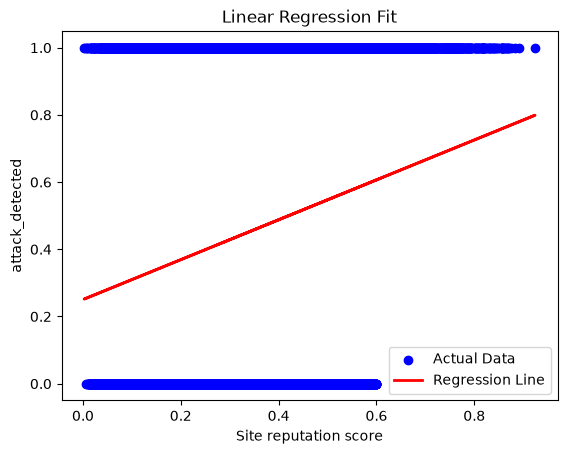

In [7]:
##2. Plot a scatter plot of ip_reputation_score vs attack_detected with fitted regression line
y_pred = linear_regression.predict(Xrep)
plt.scatter(Xrep, y, color='blue', label='Actual Data')
plt.plot(Xrep, y_pred, color='red', linewidth=2, label='Regression Line')
plt.xlabel('Site reputation score')
plt.ylabel('attack_detected')
plt.title('Linear Regression Fit')
plt.legend()
plt.show()

In [8]:
# Use stats.linregress() to calculate R^2 and p_value
slope, intercept, r_value, p_value, std_err = stats.linregress(Xrep, y)





## 3. $R^2$ score

In [9]:
Rsq = linear_regression.score(Xrep,y)
print(f"R-squared is {Rsq:.4f}")


R-squared is 0.0447


The R-squared score of 0.0447 shows that the influence of ip_reputation_score can only provide a bit under a 5% prediction of attack_detected.  
This is likely because the score's range is 0.0070 - 0.5947 for attack_detected=0 and 0.0025 - 0.9243 for attack_detected=1.  
Linear regression does not capture the binary label well.

## 4. Calculate p_value

In [10]:
print(f"P-value is {p_value}")

P-value is [nan nan nan ... nan nan nan]


The exceedingly low p-value indicates that ip_reputation_score is definitely a statistically significant predictor of attack_detected.  However, the low R-squared value shows that other features may be needed for a strong prediction.  

# Part C:
## 1. Train a linear regression model using all features to predict attack_detected

In [11]:
linear_regression.fit(X,y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](13,)","[-0. , 0.07, 0. ,..., 0.01,-0.02, 0.31]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](13,)","['network_packet_size','login_attempts','session_duration',..., 'browser_type_Firefox','browser_type_Safari','browser_type_Unknown']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-0.3601
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,13
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(13)


## 2. Print the coefficients and intercept, and identify the top 3 features (by absolute coefficient value) that most influence predictions

In [12]:
# Resolve string format problems
intercept = linear_regression.intercept_
coefficients = linear_regression.coef_

coef_df = pd.DataFrame({
    'Feature': linear_regression.feature_names_in_,
    'Coefficient': linear_regression.coef_
})

print(coef_df.to_string(index=False))
print(f"\n Intercept: {intercept:.4f} \n")

             Feature  Coefficient
 network_packet_size    -0.000009
      login_attempts     0.071718
    session_duration     0.000021
 ip_reputation_score     0.584169
       failed_logins     0.174982
 unusual_time_access     0.009287
   protocol_type_TCP     0.027293
   protocol_type_UDP     0.018999
 encryption_used_DES     0.011235
   browser_type_Edge     0.006599
browser_type_Firefox     0.007234
 browser_type_Safari    -0.018414
browser_type_Unknown     0.310656

 Intercept: -0.3601 



### The top 3 features that influence predictions are  

| | Feature Name | Coefficient |
| :--- | :--- | :--- |
| 1. | ip_reputation_score | 0.5841 |
| 2. | browser_type_Unknown | 0.3106 | 
| 3. | failed_logins | 0.1750 |
